# ***Data Grouping and Aggregation / Группировка и агрегирование данных***

# Grouping allows us to split data into groups based on one or more features and perform calculations separately for each group. In Pandas, this is done using the groupby() method.

# Группировка позволяет разделить данные на группы по значениям одного или нескольких признаков и выполнить вычисления отдельно для каждой группы. В Pandas для этого используется метод groupby().

# **Split → Apply → Combine**
# - Split — разделить данные на группы / divide data into groups;
# - Apply — применить функцию к каждой группе / apply a function to each group;
# - Combine — объединить результаты / combine the results.

# **Простая группировка / Basic Grouping**

In [1]:
import pandas as pd
df_clean = pd.read_csv("University Students 2026 New.csv")

In [2]:
df_clean.groupby("program")

# This command creates a grouping object but does not perform any calculations by itself.
# Эта команда создаёт объект группировки, но сама по себе ещё не выполняет вычислений.

In [3]:
df_clean.groupby("program")["final_score"].mean()

,final_score
program,
Cybersecurity,79.063830
Data Science,80.407407
IT Management,78.594595
Software Engineering,80.032258


# Students are grouped by program, and the mean final_score is calculated for each program.

In [4]:
# Количество студентов в каждой группе /
# Number of Students in Each Group
df_clean.groupby("program")["student_id"].count()

,student_id
program,
Cybersecurity,47
Data Science,54
IT Management,37
Software Engineering,62


# count() counts the number of non-null student_id values in each program.

In [5]:
df_clean.groupby("program").size()

,0
program,
Cybersecurity,47
Data Science,54
IT Management,37
Software Engineering,62


# count() — считает непропущенные значения / counts non-null values;
# size() — считает все строки группы / counts all rows in the group.

In [6]:
df_clean.groupby("program")["final_score"].min()

,final_score
program,
Cybersecurity,60
Data Science,58
IT Management,57
Software Engineering,62


In [7]:
df_clean.groupby("program")["final_score"].max()

,final_score
program,
Cybersecurity,91
Data Science,98
IT Management,98
Software Engineering,100


In [8]:
df_clean.groupby("program")["final_score"].median()

,final_score
program,
Cybersecurity,79.0
Data Science,80.5
IT Management,77.0
Software Engineering,80.0


In [9]:
# Grouping and Multiple Columns
df_clean.groupby("program")[
    ["math_score", "programming_score", "english_score", "final_score"]
].mean()

,math_score,programming_score,english_score,final_score
program,,,,
Cybersecurity,83.218194,80.914894,74.723404,79.063830
Data Science,83.814815,82.574074,75.611111,80.407407
IT Management,82.814258,77.297297,78.486486,78.594595
Software Engineering,82.647219,79.532258,76.790323,80.032258


# In the result, each row represents a program, while the columns show the average student performance for that program.

In [10]:
# Метод agg() / The agg() Method
df_clean.groupby("program")["final_score"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

,count,mean,median,min,max,std
program,,,,,,
Cybersecurity,47,79.063830,79.0,60,91,7.337824
Data Science,54,80.407407,80.5,58,98,7.393313
IT Management,37,78.594595,77.0,57,98,9.096579
Software Engineering,62,80.032258,80.0,62,100,7.745898


# agg() позволяет применить несколько агрегирующих функций за одну операцию.
# agg() allows multiple aggregation functions to be applied in a single operation.

In [ ]:
# Different Functions for Different Columns
df_clean.groupby("program").agg({
    "student_id": "count",
    "admission_score": "mean",
    "attendance": "mean",
    "final_score": ["mean", "min", "max"]
})

student_id admission_score attendance final_score      \
                          count            mean       mean        mean min   
program                                                                      
Cybersecurity                47       86.787234  83.127660   79.063830  60   
Data Science                 54       88.703704  81.592593   80.407407  58   
IT Management                37       89.162162  80.027027   78.594595  57   
Software Engineering         62       87.306452  84.193548   80.032258  62   

                           
                      max  
program                    
Cybersecurity          91  
Data Science           98  
IT Management          98  
Software Engineering  100

In [ ]:
# Grouping by Multiple Features
df_clean.groupby(
    ["program", "gender"]
)["final_score"].mean()

program               gender
Cybersecurity         Female    78.857143
                      Male      79.230769
Data Science          Female    81.000000
                      Male      79.666667
IT Management         Female    76.150000
                      Male      81.470588
Software Engineering  Female    79.517241
                      Male      80.484848
Name: final_score, dtype: float64

In [ ]:
# Grouping by Program and Year
df_clean.groupby(
    ["program", "year"]
)["final_score"].mean()

program               year
Cybersecurity         1       81.111111
                      2       80.777778
                      3       78.200000
                      4       77.571429
Data Science          1       77.000000
                      2       80.500000
                      3       79.250000
                      4       84.200000
IT Management         1       78.333333
                      2       79.538462
                      3       78.333333
                      4       77.666667
Software Engineering  1       79.769231
                      2       80.785714
                      3       81.125000
                      4       78.736842
Name: final_score, dtype: float64

# This allows us to compare the average final score of students from different years within each academic program.

In [11]:
# Sorting Grouped Results
df_clean.groupby(
    "program",
    as_index=False # as_index=False keeps the grouping variable program
    #as a regular column instead of making it the index.
)["final_score"].mean().sort_values(
    "final_score",
    ascending=False # ascending=False means sorting in descending order —
    #from the highest value to the lowest.
)

,program,final_score
1,Data Science,80.407407
3,Software Engineering,80.032258
0,Cybersecurity,79.063830
2,IT Management,78.594595


# First, the data are grouped, then the mean is calculated, and finally the result is sorted.

In [12]:
# Grouping Categorical Features
# how many students receive a scholarship in each program
df_clean.groupby(
    ["program", "scholarship"]
).size()

program               scholarship
Cybersecurity         No             31
                      Yes            16
Data Science          No             30
                      Yes            24
IT Management         No             24
                      Yes            13
Software Engineering  No             40
                      Yes            22
dtype: int64

In [13]:
# pivot_table() / Сводная таблица
pd.pivot_table(
    df_clean,
    values="final_score",
    index="program",
    columns="year",
    aggfunc="mean"
)

year,1,2,3,4
program,,,,
Cybersecurity,81.111111,80.777778,78.200000,77.571429
Data Science,77.000000,80.500000,79.250000,84.200000
IT Management,78.333333,79.538462,78.333333,77.666667
Software Engineering,79.769231,80.785714,81.125000,78.736842


# Строки показывают образовательные программы, столбцы — курс обучения, а значения — средний итоговый балл.По смыслу это аналог Pivot Table в Excel.
# Rows represent academic programs, columns represent years of study, and values show the average final score.


In [14]:
# Multiple Measures in pivot_table()
pd.pivot_table(
    df_clean,
    values=["attendance", "final_score"],
    index="program",
    columns="year",
    aggfunc="mean"
)

attendance                                  final_score  \
year                          1          2          3          4           1   
program                                                                        
Cybersecurity         85.666667  80.777778  81.533333  84.714286   81.111111   
Data Science          79.846154  80.642857  81.833333  83.800000   77.000000   
IT Management         83.833333  80.230769  77.000000  80.222222   78.333333   
Software Engineering  84.076923  85.714286  85.875000  81.736842   79.769231   

                                                       
year                          2          3          4  
program                                                
Cybersecurity         80.777778  78.200000  77.571429  
Data Science          80.500000  79.250000  84.200000  
IT Management         79.538462  78.333333  77.666667  
Software Engineering  80.785714  81.125000  78.736842

# ***Корреляционный анализ / Correlation Analysis***

# Корреляционный анализ используется для оценки силы и направления взаимосвязи между числовыми признаками.
# Correlation analysis is used to evaluate the strength and direction of relationships between numerical features.

In [15]:
df_clean["attendance"].corr(df_clean["final_score"])

np.float64(0.2486962495839429)

# The correlation coefficient ranges from -1 to 1.

# Положительное значение означает, что более высокая посещаемость имеет тенденцию сопровождаться более высоким итоговым баллом. Корреляция сама по себе не доказывает причинно-следственную связь.
# A positive value means that higher attendance tends to be associated with a higher final score. Correlation itself does not establish causation.

In [16]:
# Корреляционная матрица / Correlation Matrix
numeric_columns = [
    "admission_score",
    "math_score",
    "programming_score",
    "english_score",
    "attendance",
    "assignments",
    "final_score"
]

correlation_matrix = df_clean[numeric_columns].corr()

correlation_matrix

,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score
admission_score,1.000000,0.594307,0.187716,-0.054725,-0.064860,0.073125,0.306237
math_score,0.594307,1.000000,0.410717,-0.039936,0.065345,0.256679,0.590259
programming_score,0.187716,0.410717,1.000000,-0.106805,0.050985,0.567902,0.678177
english_score,-0.054725,-0.039936,-0.106805,1.000000,-0.015331,-0.068072,0.165048
attendance,-0.064860,0.065345,0.050985,-0.015331,1.000000,0.383287,0.248696
assignments,0.073125,0.256679,0.567902,-0.068072,0.383287,1.000000,0.618500
final_score,0.306237,0.590259,0.678177,0.165048,0.248696,0.618500,1.000000


# By default, corr() calculates the Pearson correlation coefficient for each pair of numerical features.
# Метод corr() по умолчанию рассчитывает коэффициент корреляции Пирсона для каждой пары числовых признаков.

In [17]:
# Корреляция с итоговой оценкой / Correlation with Final Score
correlation_matrix["final_score"].sort_values(ascending=False)

,final_score
final_score,1.000000
programming_score,0.678177
assignments,0.618500
math_score,0.590259
admission_score,0.306237
attendance,0.248696
english_score,0.165048


# **Combining DataFrames / Объединение таблиц**

# In real-world tasks, data are often stored in multiple tables. For example, student information may be stored in one file, faculty information in another, and additional course results in a third. Pandas provides several methods for combining tables: merge(), join(), and concat().

# В реальных задачах данные часто хранятся не в одной таблице. Например, основная информация о студентах может находиться в одном файле, информация о факультетах — в другом, а результаты дополнительных курсов — в третьем. Pandas предоставляет несколько способов объединения таблиц: merge(), join() и concat().

# **merge()** — объединение по общему ключу / Combining Data Using a Common Key

# Let's create an additional table with information about students. / Создадим дополнительную таблицу с информацией о студентах

In [28]:
student_status = pd.DataFrame({
    "student_id": ["ST001", "ST002", "ST003", "ST004", "ST005","ST201"],
    "status": ["Active", "Active", "Exchange", "Active", "Academic Leave","Exchange"]
})

student_status

,student_id,status
0,ST001,Active
1,ST002,Active
2,ST003,Exchange
3,ST004,Active
4,ST005,Academic Leave
5,ST201,Exchange


In [31]:
merged_df = pd.merge(
    df_clean,
    student_status,
    on="student_id",
    how="inner"
)

merged_df.head()

,student_id,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,status
0,ST001,Male,Pavlodar,Software Engineering,4,72,75.0,59.0,80.0,61.0,66,62,No,Yes,2026-03-09,Active
1,ST002,Female,Aktobe,IT Management,2,98,72.0,65.0,69.0,82.0,71,66,Yes,Yes,2023-09-20,Active
2,ST003,Male,Almaty,Cybersecurity,4,92,68.0,75.0,76.0,82.0,66,66,No,Yes,2026-07-10,Exchange
3,ST004,Male,Astana,Data Science,4,117,99.0,100.0,69.0,100.0,100,98,Yes,No,2023-10-28,Active
4,ST005,Female,Astana,IT Management,3,93,84.0,100.0,95.0,69.0,87,96,Yes,No,2023-09-13,Academic Leave


# Параметр on="student_id" определяет столбец-ключ, по которому сопоставляются строки двух таблиц.
# The on="student_id" parameter specifies the key column used to match rows from the two tables.

# Types of merge()/Типы объединения merge()
# **inner**
# **left**
# **right**
# **outer**

In [32]:
# inner
pd.merge(
    df_clean,
    student_status,
    on="student_id",
    how="inner"
)

,student_id,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,status
0,ST001,Male,Pavlodar,Software Engineering,4,72,75.0,59.0,80.0,61.0,66,62,No,Yes,2026-03-09,Active
1,ST002,Female,Aktobe,IT Management,2,98,72.0,65.0,69.0,82.0,71,66,Yes,Yes,2023-09-20,Active
2,ST003,Male,Almaty,Cybersecurity,4,92,68.0,75.0,76.0,82.0,66,66,No,Yes,2026-07-10,Exchange
3,ST004,Male,Astana,Data Science,4,117,99.0,100.0,69.0,100.0,100,98,Yes,No,2023-10-28,Active
4,ST005,Female,Astana,IT Management,3,93,84.0,100.0,95.0,69.0,87,96,Yes,No,2023-09-13,Academic Leave


# Оставляет только студентов, присутствующих в обеих таблицах.
# Keeps only students that are present in both tables.

In [33]:
# left
pd.merge(
    df_clean,
    student_status,
    on="student_id",
    how="left"
)

,student_id,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,status
0,ST001,Male,Pavlodar,Software Engineering,4,72,75.0,59.0,80.0,61.0,66,62,No,Yes,2026-03-09,Active
1,ST002,Female,Aktobe,IT Management,2,98,72.0,65.0,69.0,82.0,71,66,Yes,Yes,2023-09-20,Active
2,ST003,Male,Almaty,Cybersecurity,4,92,68.0,75.0,76.0,82.0,66,66,No,Yes,2026-07-10,Exchange
3,ST004,Male,Astana,Data Science,4,117,99.0,100.0,69.0,100.0,100,98,Yes,No,2023-10-28,Active
4,ST005,Female,Astana,IT Management,3,93,84.0,100.0,95.0,69.0,87,96,Yes,No,2023-09-13,Academic Leave
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,ST196,Female,Almaty,Software Engineering,3,81,93.0,93.0,59.0,87.0,85,88,Yes,Yes,2025-03-24,NaN
196,ST197,Male,Pavlodar,Cybersecurity,3,87,82.0,87.0,55.0,77.0,83,78,No,Yes,2024-01-14,NaN
197,ST198,Male,Almaty,Cybersecurity,3,91,83.0,98.0,77.0,83.0,94,87,No,No,2023-10-28,NaN
198,ST199,Female,Almaty,IT Management,1,76,67.0,88.0,90.0,68.0,74,73,No,Yes,2026-03-18,NaN


# Сохраняет всех студентов из левой таблицы df_clean и добавляет найденную информацию из второй таблицы.
# Keeps all students from the left DataFrame df_clean and adds matching information from the second DataFrame.

In [34]:
# right
pd.merge(
    df_clean,
    student_status,
    on="student_id",
    how="right"
)

,student_id,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,status
0,ST001,Male,Pavlodar,Software Engineering,4.0,72.0,75.0,59.0,80.0,61.0,66.0,62.0,No,Yes,2026-03-09,Active
1,ST002,Female,Aktobe,IT Management,2.0,98.0,72.0,65.0,69.0,82.0,71.0,66.0,Yes,Yes,2023-09-20,Active
2,ST003,Male,Almaty,Cybersecurity,4.0,92.0,68.0,75.0,76.0,82.0,66.0,66.0,No,Yes,2026-07-10,Exchange
3,ST004,Male,Astana,Data Science,4.0,117.0,99.0,100.0,69.0,100.0,100.0,98.0,Yes,No,2023-10-28,Active
4,ST005,Female,Astana,IT Management,3.0,93.0,84.0,100.0,95.0,69.0,87.0,96.0,Yes,No,2023-09-13,Academic Leave
5,ST201,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Exchange


# Сохраняет все строки правой таблицы.
# Keeps all rows from the right DataFrame.

In [35]:
# outer
pd.merge(
    df_clean,
    student_status,
    on="student_id",
    how="outer"
)

,student_id,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,status
0,ST001,Male,Pavlodar,Software Engineering,4.0,72.0,75.0,59.0,80.0,61.0,66.0,62.0,No,Yes,2026-03-09,Active
1,ST002,Female,Aktobe,IT Management,2.0,98.0,72.0,65.0,69.0,82.0,71.0,66.0,Yes,Yes,2023-09-20,Active
2,ST003,Male,Almaty,Cybersecurity,4.0,92.0,68.0,75.0,76.0,82.0,66.0,66.0,No,Yes,2026-07-10,Exchange
3,ST004,Male,Astana,Data Science,4.0,117.0,99.0,100.0,69.0,100.0,100.0,98.0,Yes,No,2023-10-28,Active
4,ST005,Female,Astana,IT Management,3.0,93.0,84.0,100.0,95.0,69.0,87.0,96.0,Yes,No,2023-09-13,Academic Leave
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,ST197,Male,Pavlodar,Cybersecurity,3.0,87.0,82.0,87.0,55.0,77.0,83.0,78.0,No,Yes,2024-01-14,NaN
197,ST198,Male,Almaty,Cybersecurity,3.0,91.0,83.0,98.0,77.0,83.0,94.0,87.0,No,No,2023-10-28,NaN
198,ST199,Female,Almaty,IT Management,1.0,76.0,67.0,88.0,90.0,68.0,74.0,73.0,No,Yes,2026-03-18,NaN
199,ST200,Female,Almaty,Cybersecurity,2.0,97.0,86.0,78.0,76.0,85.0,76.0,72.0,Yes,No,2026-06-16,NaN


# Сохраняет все записи из обеих таблиц независимо от наличия соответствия.
# Keeps all records from both DataFrames, regardless of whether a match exists.

# **Different Key Names\Разные названия ключей**

In [37]:
student_status = pd.DataFrame({
    "student_code": ["ST001", "ST002", "ST003"],
    "status": ["Active", "Active", "Exchange"]
})

In [41]:
merged_df = pd.merge(
    df_clean,
    student_status,
    left_on="student_id",
    right_on="student_code",
    how="right"
)

In [42]:
merged_df.head()

,student_id,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,student_code,status
0,ST001,Male,Pavlodar,Software Engineering,4,72,75.0,59.0,80.0,61.0,66,62,No,Yes,2026-03-09,ST001,Active
1,ST002,Female,Aktobe,IT Management,2,98,72.0,65.0,69.0,82.0,71,66,Yes,Yes,2023-09-20,ST002,Active
2,ST003,Male,Almaty,Cybersecurity,4,92,68.0,75.0,76.0,82.0,66,66,No,Yes,2026-07-10,ST003,Exchange


# left_on задаёт ключ левой таблицы, right_on — ключ правой.
# left_on specifies the key in the left DataFrame, while right_on specifies the key in the right DataFrame.

# **join()** — объединение по индексу / Joining by Index
# join() особенно удобен, когда таблицы необходимо объединить по индексам.
# join() is particularly convenient when DataFrames need to be combined using their indexes.

In [43]:
status = student_status.set_index("student_code")
students = df_clean.set_index("student_id")
joined_df = students.join(
    status,
    how="left"
)
joined_df.head()

,gender,city,program,year,admission_score,math_score,programming_score,english_score,attendance,assignments,final_score,scholarship,dormitory,admission_date,status
student_id,,,,,,,,,,,,,,,
ST001,Male,Pavlodar,Software Engineering,4,72,75.0,59.0,80.0,61.0,66,62,No,Yes,2026-03-09,Active
ST002,Female,Aktobe,IT Management,2,98,72.0,65.0,69.0,82.0,71,66,Yes,Yes,2023-09-20,Active
ST003,Male,Almaty,Cybersecurity,4,92,68.0,75.0,76.0,82.0,66,66,No,Yes,2026-07-10,Exchange
ST004,Male,Astana,Data Science,4,117,99.0,100.0,69.0,100.0,100,98,Yes,No,2023-10-28,NaN
ST005,Female,Astana,IT Management,3,93,84.0,100.0,95.0,69.0,87,96,Yes,No,2023-09-13,NaN


# merge() чаще используют для объединения по столбцам, а join() удобно использовать для объединения по индексам.
# merge() is commonly used for column-based matching, while join() is convenient for index-based matching.

# **concat()** — объединение таблиц / Concatenating DataFrames

In [45]:
# Suppose the student data is split:
students_part1 = df_clean.iloc[:100]
students_part2 = df_clean.iloc[100:]

In [46]:
students_part1.shape

(100, 15)

In [47]:
students_part2.shape

(100, 15)

In [48]:
students_all = pd.concat(
    [students_part1, students_part2],
    axis=0
)
students_all.shape

(200, 15)

# axis=0 означает добавление строк друг под другом.
# axis=0 means combining DataFrames vertically by rows.

In [51]:
students_all = pd.concat(
    [students_part1, students_part2],
    ignore_index=True
)
students_all.shape

(200, 15)

# ignore_index=True создаёт новый последовательный индекс после объединения.
# ignore_index=True creates a new sequential index after concatenation.

# **concat()** по столбцам / Column-wise concat()

In [52]:
student_info = df_clean[
    ["student_id", "gender", "program"]
]
student_scores = df_clean[
    ["math_score", "programming_score", "final_score"]
]
combined_df = pd.concat(
    [student_info, student_scores],
    axis=1
)
combined_df.head()

,student_id,gender,program,math_score,programming_score,final_score
0,ST001,Male,Software Engineering,75.0,59.0,62
1,ST002,Female,IT Management,72.0,65.0,66
2,ST003,Male,Cybersecurity,68.0,75.0,66
3,ST004,Male,Data Science,99.0,100.0,98
4,ST005,Female,IT Management,84.0,100.0,96


# axis=1 означает объединение по столбцам.
# axis=1 means combining DataFrames by columns.
# axis=0 → rows
# axis=1 → columns

**merge, join, or concat?**

# | Метод | Когда использовать / When to use |

# | `merge()` | Связать таблицы по ключевому столбцу / Match tables using a key column |
# | `join()` | Связать преимущественно по индексам / Join primarily by index |
# | `concat(axis=0)` | Добавить строки / Add rows |
# | `concat(axis=1)` | Добавить столбцы / Add columns |

# merge() ищет соответствия между записями, а concat() преимущественно складывает существующие структуры вместе.
# merge() matches related records, while concat() primarily combines existing structures.

# **Подготовка структурированных данных для Scikit-learn / Preparing Structured Data for Scikit-learn**

# После очистки и преобразования DataFrame можно подготовить данные для использования алгоритмами машинного обучения. Обычно данные разделяются на матрицу признаков X и целевую переменную y.
# After cleaning and transforming a DataFrame, the data can be prepared for machine learning algorithms. Typically, the dataset is divided into a feature matrix X and a target variable y.
# Допустим, наша задача:
# На основе учебных показателей студента прогнозировать его итоговый балл final_score.
# Predict a student's final_score based on academic characteristics.

In [53]:
# Selecting Features and Target / Выбор признаков и целевой переменной
features = [
    "admission_score",
    "math_score",
    "programming_score",
    "english_score",
    "attendance",
    "assignments"
]

X = df_clean[features]
y = df_clean["final_score"]

In [54]:
X.head()

,admission_score,math_score,programming_score,english_score,attendance,assignments
0,72,75.0,59.0,80.0,61.0,66
1,98,72.0,65.0,69.0,82.0,71
2,92,68.0,75.0,76.0,82.0,66
3,117,99.0,100.0,69.0,100.0,100
4,93,84.0,100.0,95.0,69.0,87


In [55]:
y.head()

,final_score
0,62
1,66
2,66
3,98
4,96


In [56]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 6)
y shape: (200,)


# X содержит входные признаки модели, а y — значение, которое модель должна научиться прогнозировать.
# X contains the model input features, while y contains the value that the model should learn to predict.

# **Разделение на обучающую и тестовую выборки / Train-Test Split**

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# test_size=0.2 означает, что 20% данных используются для тестирования, а 80% — для обучения.
# test_size=0.2 means that 20% of the data are used for testing and 80% for training.

In [59]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 6)
X_test: (40, 6)
y_train: (160,)
y_test: (40,)


# **Несбалансированные данные / Imbalanced Data**

# Набор данных называется несбалансированным, если разные классы целевой переменной представлены существенно разным количеством наблюдений.
# A dataset is considered imbalanced when the classes of the target variable contain substantially different numbers of observations.

# Проверка баланса классов / Checking Class Balance

In [60]:
df_clean["scholarship"].value_counts()

,count
scholarship,
No,125
Yes,75


In [61]:
class_distribution = (
    df_clean["scholarship"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class_distribution

,proportion
scholarship,
No,62.5
Yes,37.5


# **Why Is Class Imbalance a Problem?**

# Поэтому высокая accuracy не всегда означает хорошую модель, особенно при сильном дисбалансе классов.
# Therefore, high accuracy does not always indicate a good model, especially when the classes are strongly imbalanced.

# Визуализация распределения классов / Visualizing Class Distribution

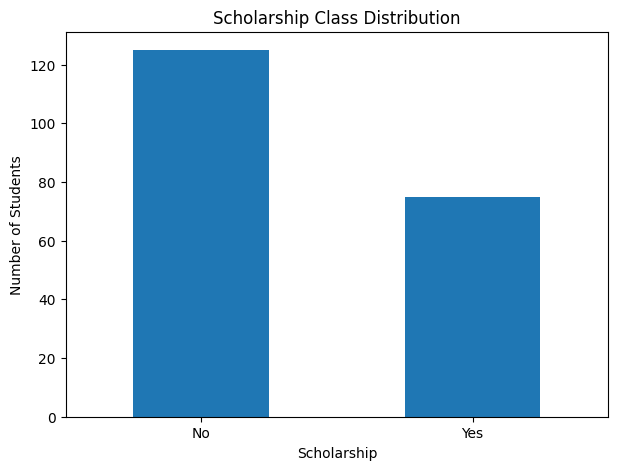

In [62]:
import matplotlib.pyplot as plt

df_clean["scholarship"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Scholarship Class Distribution")
plt.xlabel("Scholarship")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

# **Stratified Train-Test Split**

In [69]:
X = df_clean[
    [
        "math_score",
        "programming_score",
        "english_score",
        "attendance",
        "assignments"
    ]
]

y = df_clean["scholarship"]

In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [72]:
print(y.value_counts(normalize=True))

scholarship
No     0.625
Yes    0.375
Name: proportion, dtype: float64


In [73]:
print(y_train.value_counts(normalize=True))

scholarship
No     0.625
Yes    0.375
Name: proportion, dtype: float64


In [ ]:
print(y_test.value_counts(normalize=True))

# stratify=y старается сохранить примерно одинаковое соотношение классов в обучающей и тестовой выборках.
# stratify особенно полезен в задачах классификации, когда необходимо сохранить распределение классов при разделении данных.
# stratify=y preserves approximately the same class proportions in the training and test sets.
# stratify is particularly useful in classification tasks when class proportions should be preserved during the train-test split.


# Pandas является не просто библиотекой для просмотра таблиц. Он обеспечивает полный этап подготовки структурированных данных перед статистическим анализом и машинным обучением.
# Pandas is not simply a library for viewing tables. It provides a complete workflow for preparing structured data before statistical analysis and machine learning.